# 02 · Features
Cada característica se calcula con información disponible hasta ese momento. La volatilidad
futura se calcula con los rendimientos de \(t+1\) a \(t+5\).

## Características derivadas (En función de hallazgos del EDA)

| Característica | Cálculo | Evidencia del EDA que motiva su inclusión | Disponibilidad al emitir la alerta | Codificación |
|---|---|---|---|---|
| `VOL_HIST_20` | Desviación estándar de los rendimientos diarios de las últimas 20 ruedas, incluida la rueda actual. | La volatilidad móvil mostró períodos de calma y turbulencia. Evaluaremos si la dispersión reciente ayuda a anticipar la volatilidad futura. | El cierre ajustado de hoy y los cierres anteriores están disponibles al cierre de la rueda. | Numérica continua. |
| `VOLUMEN_REL_20` | Volumen de la rueda actual dividido por el promedio de las 20 ruedas anteriores. | El volumen fue la variable original con mayor asociación de Spearman con la volatilidad futura (0,116). Evaluaremos si la desviación respecto de su nivel habitual aporta información. | El volumen de hoy está disponible al cierre. La referencia se calcula con ruedas anteriores. | Numérica continua. |
| `RANGO_INTRADIA_REL` | Diferencia entre el máximo y el mínimo de la rueda actual, dividida por su precio de apertura. | Los niveles de precios tuvieron asociaciones de Spearman entre 0,049 y 0,053 con la volatilidad futura. Evaluaremos si la amplitud relativa del movimiento intradiario resulta más informativa. | La apertura, el máximo y el mínimo de la rueda están disponibles al cierre. | Numérica continua. |


In [1]:
import sys
from pathlib import Path

import pandas as pd

raiz = Path.cwd()
if raiz.name == "notebooks":
    raiz = raiz.parent

sys.path.insert(0, str(raiz))

from src.datos import cargar_obt

df = cargar_obt()

print(f"Filas: {df.shape[0]:,} | Columnas: {df.shape[1]}")
display(df[["TRADE_DATE", "SYMBOL", "ADJ_CLOSE_PRICE", "VOLUME"]].head())

Filas: 4,087 | Columnas: 19


,TRADE_DATE,SYMBOL,ADJ_CLOSE_PRICE,VOLUME
0,2010-07-01,AAPL,7.426302,1022896000
1,2010-07-02,AAPL,7.380276,693842800
2,2010-07-06,AAPL,7.430788,615235600
3,2010-07-07,AAPL,7.730850,654556000
4,2010-07-08,AAPL,7.713517,738144400


In [2]:
mercado = df.sort_values("TRADE_DATE").set_index("TRADE_DATE")

retorno_pct = mercado["ADJ_CLOSE_PRICE"].pct_change(fill_method=None).mul(100)

volumen_habitual = mercado["VOLUME"].shift(1).rolling(20).mean()
apertura = mercado["OPEN_PRICE"]

features = pd.DataFrame({
    "VOL_HIST_20": retorno_pct.rolling(20).std(ddof=1),
    "VOLUMEN_REL_20": mercado["VOLUME"].div(
        volumen_habitual.where(volumen_habitual > 0)
    ),
    "RANGO_INTRADIA_REL": (
        mercado["HIGH_PRICE"] - mercado["LOW_PRICE"]
    ).div(apertura.where(apertura > 0)),
})

display(features.head(25).round(4))

resumen_features = features.describe().T
resumen_features["Nulos"] = features.isna().sum()
display(resumen_features.round(4))

,VOL_HIST_20,VOLUMEN_REL_20,RANGO_INTRADIA_REL
TRADE_DATE,,,
2010-07-01,NaN,NaN,0.0455
2010-07-02,NaN,NaN,0.0309
2010-07-06,NaN,NaN,0.0265
2010-07-07,NaN,NaN,0.0360
2010-07-08,NaN,NaN,0.0305
2010-07-09,NaN,NaN,0.0185
2010-07-12,NaN,NaN,0.0270
2010-07-13,NaN,NaN,0.0389
2010-07-14,NaN,NaN,0.0273


,count,mean,std,min,25%,50%,75%,max,Nulos
VOL_HIST_20,4067.0,1.6170,0.7188,0.4558,1.1716,1.4686,1.8918,6.8004,20
VOLUMEN_REL_20,4067.0,1.0089,0.4194,0.2730,0.7568,0.9091,1.1430,6.7800,20
RANGO_INTRADIA_REL,4087.0,0.0200,0.0115,0.0041,0.0126,0.0173,0.0241,0.1771,0


Además se van a experimentar con otras features, el retorno absoluto sin y con reuda de un día. Las volatilidades con varias ruedas y ratios. Medias móviles y momentos como features de tendencia. Las distancias SMA entre tendencia y cambio acumulado y GAP para tener una parte que nos de algo de información de como la clausura termina en la apertura. 

In [3]:
cierre_ajustado = mercado["ADJ_CLOSE_PRICE"]

# Rendimientos con signo y magnitud de los movimientos recientes.
for rezago in range(5):
    features[f"RET_LAG_{rezago}"] = retorno_pct.shift(rezago)

features["ABS_RET_0"] = retorno_pct.abs()
features["ABS_RET_1"] = retorno_pct.abs().shift(1)

# Volatilidad reciente y comparación entre horizontes.
features["VOL_HIST_5"] = retorno_pct.rolling(5).std(ddof=1)
features["VOL_HIST_60"] = retorno_pct.rolling(60).std(ddof=1)
features["VOL_RATIO_5_20"] = features["VOL_HIST_5"].div(
    features["VOL_HIST_20"].where(features["VOL_HIST_20"] > 0)
)

# Tendencia y posición relativa del precio.
for ventana in (20, 50):
    media_movil = cierre_ajustado.rolling(ventana).mean()
    features[f"DIST_SMA_{ventana}"] = cierre_ajustado.div(media_movil).sub(1)

features["MOM_10"] = cierre_ajustado.pct_change(10, fill_method=None)

# Gap de apertura con ambos precios en una escala ajustada comparable.
cierre = mercado["CLOSE_PRICE"]
factor_ajuste = cierre_ajustado.div(cierre.where(cierre > 0))
apertura_ajustada = mercado["OPEN_PRICE"].mul(factor_ajuste)
features["GAP_APERTURA"] = apertura_ajustada.div(
    cierre_ajustado.shift(1)
).sub(1)

# Mes de la fecha de alerta (1 a 12). Se codificará como categórica.
features["MES"] = mercado.index.month

In [4]:
nulos_despues_del_inicio = features.iloc[60:].isna().sum()
display(nulos_despues_del_inicio.rename("NaN después de la rueda 60").to_frame())

,NaN después de la rueda 60
VOL_HIST_20,0
VOLUMEN_REL_20,0
RANGO_INTRADIA_REL,0
RET_LAG_0,0
RET_LAG_1,0
RET_LAG_2,0
RET_LAG_3,0
RET_LAG_4,0
ABS_RET_0,0
ABS_RET_1,0


# Preparación y Esquema de Validación

In [5]:
# Alineación Target con Features

horizonte = 5

vol_futura_5 = (
    retorno_pct.rolling(horizonte, min_periods=horizonte)
    .std(ddof=1)
    .shift(-horizonte)
    .rename("VOL_FUTURA_5")
)

datos_modelado = features.iloc[60:].join(vol_futura_5)
datos_modelado = datos_modelado.dropna(subset=["VOL_FUTURA_5"])

print(f"Dimensiones: {datos_modelado.shape}")
print(f"Primera fecha utilizable: {datos_modelado.index.min().date()}")
print(f"Última fecha utilizable: {datos_modelado.index.max().date()}")
display(datos_modelado.tail(3))

Dimensiones: (4022, 19)
Primera fecha utilizable: 2010-09-27
Última fecha utilizable: 2026-09-23


,VOL_HIST_20,VOLUMEN_REL_20,RANGO_INTRADIA_REL,RET_LAG_0,RET_LAG_1,RET_LAG_2,RET_LAG_3,RET_LAG_4,ABS_RET_0,ABS_RET_1,VOL_HIST_5,VOL_HIST_60,VOL_RATIO_5_20,DIST_SMA_20,DIST_SMA_50,MOM_10,GAP_APERTURA,MES,VOL_FUTURA_5
TRADE_DATE,,,,,,,,,,,,,,,,,,,
2026-09-21,1.358953,0.804889,0.019655,0.847896,-0.258165,1.380826,0.322930,-0.522388,0.847896,0.258165,0.781356,1.843934,0.574969,0.045842,0.057647,0.059412,-0.002529,9,0.969841
2026-09-22,1.359640,0.949228,0.019374,0.227141,0.847896,-0.258165,1.380826,0.322930,0.227141,0.847896,0.627977,1.807759,0.461870,0.043484,0.058549,0.074410,0.003422,9,1.495108
2026-09-23,1.382971,0.732990,0.018471,-0.803535,0.227141,0.847896,-0.258165,1.380826,0.803535,0.227141,0.866138,1.808615,0.626288,0.030806,0.048578,0.068751,0.003915,9,1.665262


In [6]:
#Traint y Test 

datos_modelado = datos_modelado.sort_index()

# Reservar el último 20 % de las fechas utilizables.
posicion_corte = int(len(datos_modelado) * 0.80)
inicio_prueba = datos_modelado.index[posicion_corte]

# Para cada fecha de alerta, identificar la última rueda que usa su etiqueta.
fin_ventana_target = mercado.index.to_series().shift(-horizonte)
fin_ventana_modelado = fin_ventana_target.reindex(datos_modelado.index)

es_previo_a_prueba = datos_modelado.index < inicio_prueba
ventana_termina_antes = fin_ventana_modelado < inicio_prueba

entrenamiento = datos_modelado.loc[
    es_previo_a_prueba & ventana_termina_antes
].copy()
holdout = datos_modelado.loc[~es_previo_a_prueba].copy()
fechas_excluidas = datos_modelado.index[
    es_previo_a_prueba & ~ventana_termina_antes
]

assert fin_ventana_target.loc[entrenamiento.index].max() < holdout.index.min()

resumen_particion = pd.DataFrame({
    "Conjunto": ["Entrenamiento", "Hold-out"],
    "Filas": [len(entrenamiento), len(holdout)],
    "Primera fecha": [entrenamiento.index.min(), holdout.index.min()],
    "Última fecha": [entrenamiento.index.max(), holdout.index.max()],
})

display(resumen_particion)
print(f"Fechas excluidas entre conjuntos: {len(fechas_excluidas)}")
print(
    "Última rueda usada por una etiqueta de entrenamiento:",
    fin_ventana_target.loc[entrenamiento.index].max().date(),
)

,Conjunto,Filas,Primera fecha,Última fecha
0,Entrenamiento,3212,2010-09-27,2023-06-30
1,Hold-out,805,2023-07-11,2026-09-23


Fechas excluidas entre conjuntos: 5
Última rueda usada por una etiqueta de entrenamiento: 2023-07-10


In [7]:
#Split

from sklearn.model_selection import TimeSeriesSplit

cv_temporal = TimeSeriesSplit(n_splits=5, gap=horizonte)
resumen_pliegues = []

for numero, (idx_train, idx_val) in enumerate(
    cv_temporal.split(entrenamiento), start=1
):
    fechas_train = entrenamiento.index[idx_train]
    fechas_val = entrenamiento.index[idx_val]
    fin_target_train = fin_ventana_target.loc[fechas_train].max()

    assert fin_target_train < fechas_val[0], (
        f"La ventana del target cruza a validación en el pliegue {numero}"
    )

    resumen_pliegues.append({
        "Pliegue": numero,
        "Filas train": len(fechas_train),
        "Fin train": fechas_train[-1].date(),
        "Fin de la última ventana del target train": fin_target_train.date(),
        "Filas validación": len(fechas_val),
        "Inicio validación": fechas_val[0].date(),
        "Fin validación": fechas_val[-1].date(),
    })

display(pd.DataFrame(resumen_pliegues))

,Pliegue,Filas train,Fin train,Fin de la última ventana del target train,Filas validación,Inicio validación,Fin validación
0,1,532,2012-11-05,2012-11-12,535,2012-11-13,2014-12-29
1,2,1067,2014-12-19,2014-12-29,535,2014-12-30,2017-02-13
2,3,1602,2017-02-06,2017-02-13,535,2017-02-14,2019-04-01
3,4,2137,2019-03-25,2019-04-01,535,2019-04-02,2021-05-14
4,5,2672,2021-05-07,2021-05-14,535,2021-05-17,2023-06-30


In [8]:
#Calculando Variable Objetivo

resumen_etiquetas = []

for numero, (idx_train, idx_val) in enumerate(
    cv_temporal.split(entrenamiento), start=1
):
    vol_train = entrenamiento.iloc[idx_train]["VOL_FUTURA_5"]
    vol_val = entrenamiento.iloc[idx_val]["VOL_FUTURA_5"]

    umbral_vol = vol_train.quantile(0.80)
    y_train = vol_train.gt(umbral_vol).astype(int)
    y_val = vol_val.gt(umbral_vol).astype(int)

    resumen_etiquetas.append({
        "Pliegue": numero,
        "P80 train (%)": umbral_vol,
        "Positivos train": int(y_train.sum()),
        "% positivos train": 100 * y_train.mean(),
        "Positivos validación": int(y_val.sum()),
        "Negativos validación": int(y_val.eq(0).sum()),
        "% positivos validación": 100 * y_val.mean(),
    })

display(pd.DataFrame(resumen_etiquetas).round(3))

,Pliegue,P80 train (%),Positivos train,% positivos train,Positivos validación,Negativos validación,% positivos validación
0,1,1.883,107,20.113,106,429,19.813
1,2,1.890,214,20.056,110,425,20.561
2,3,1.895,321,20.037,105,430,19.626
3,4,1.892,428,20.028,218,317,40.748
4,5,2.064,535,20.022,133,402,24.860


In [9]:
from src.pipeline import crear_preprocesador

X_desarrollo = entrenamiento.drop(columns="VOL_FUTURA_5")
columnas_numericas = columnas_numericas = X_desarrollo.columns.drop("MES").tolist()

idx_train, idx_val = next(cv_temporal.split(X_desarrollo))

preprocesador = crear_preprocesador(columnas_numericas)
X_train_preparado = preprocesador.fit_transform(X_desarrollo.iloc[idx_train])
X_val_preparado = preprocesador.transform(X_desarrollo.iloc[idx_val])

print("Entrenamiento transformado:", X_train_preparado.shape)
print("Validación transformada:", X_val_preparado.shape)
print("Columnas transformadas:", preprocesador.get_feature_names_out().tolist())

Entrenamiento transformado: (532, 29)
Validación transformada: (535, 29)
Columnas transformadas: ['numericas__VOL_HIST_20', 'numericas__VOLUMEN_REL_20', 'numericas__RANGO_INTRADIA_REL', 'numericas__RET_LAG_0', 'numericas__RET_LAG_1', 'numericas__RET_LAG_2', 'numericas__RET_LAG_3', 'numericas__RET_LAG_4', 'numericas__ABS_RET_0', 'numericas__ABS_RET_1', 'numericas__VOL_HIST_5', 'numericas__VOL_HIST_60', 'numericas__VOL_RATIO_5_20', 'numericas__DIST_SMA_20', 'numericas__DIST_SMA_50', 'numericas__MOM_10', 'numericas__GAP_APERTURA', 'calendario__MES_1', 'calendario__MES_2', 'calendario__MES_3', 'calendario__MES_4', 'calendario__MES_5', 'calendario__MES_6', 'calendario__MES_7', 'calendario__MES_8', 'calendario__MES_9', 'calendario__MES_10', 'calendario__MES_11', 'calendario__MES_12']


## Dia_Semana vs Mes

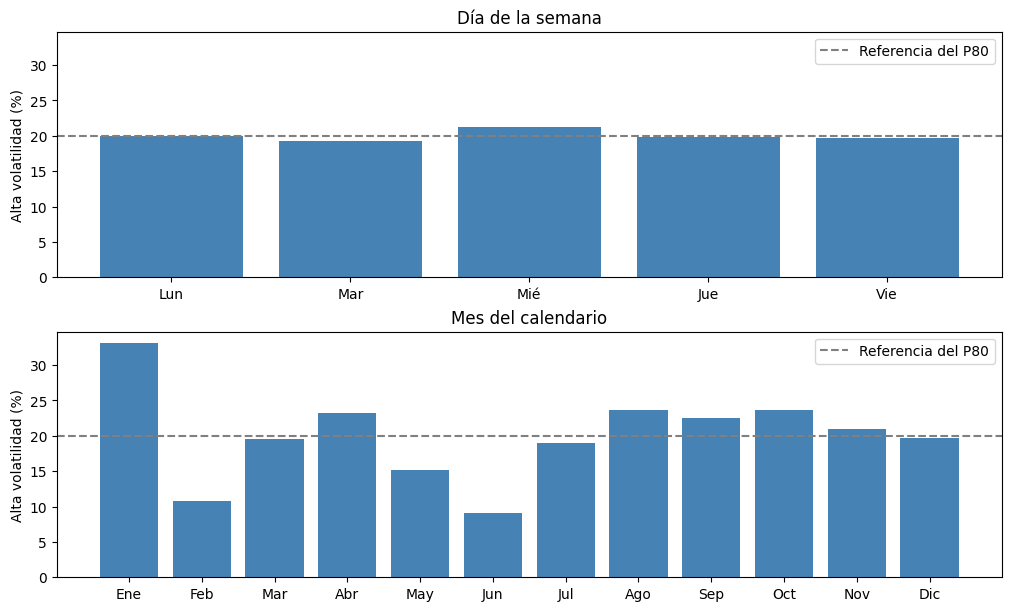

In [10]:
from matplotlib import pyplot as plt

vol_futura = entrenamiento["VOL_FUTURA_5"]
p80 = vol_futura.quantile(0.80)

fig, ejes = plt.subplots(2, 1, figsize=(10, 6), layout="constrained")

calendarios = [
    ("Día de la semana", vol_futura.index.dayofweek, range(5),
     ["Lun", "Mar", "Mié", "Jue", "Vie"]),
    ("Mes del calendario", vol_futura.index.month, range(1, 13),
     ["Ene", "Feb", "Mar", "Abr", "May", "Jun",
      "Jul", "Ago", "Sep", "Oct", "Nov", "Dic"]),
]

for ax, (titulo, grupos, orden, etiquetas) in zip(ejes, calendarios):
    tasa_alta = vol_futura.gt(p80).groupby(grupos).mean().reindex(orden) * 100
    ax.bar(etiquetas, tasa_alta, color="steelblue")
    ax.axhline(20, color="gray", linestyle="--", label="Referencia del P80")
    ax.set(title=titulo, ylabel="Alta volatilidad (%)")
    ax.legend()

ejes[0].sharey(ejes[1])
plt.show()

## Prueba de data leakage

In [ ]:
from src.features import construir_features

features = construir_features(df)

mercado = df.sort_values("TRADE_DATE").set_index("TRADE_DATE")
retorno_pct = features["RET_LAG_0"]

display(features.head())

features = construir_features(df)

# Estas variables las usan las celdas del target y la partición.
mercado = df.sort_values("TRADE_DATE").set_index("TRADE_DATE")
retorno_pct = features["RET_LAG_0"]

display(features.head())

,VOL_HIST_20,VOLUMEN_REL_20,RANGO_INTRADIA_REL,RET_LAG_0,RET_LAG_1,RET_LAG_2,RET_LAG_3,RET_LAG_4,ABS_RET_0,ABS_RET_1,VOL_HIST_5,VOL_HIST_60,VOL_RATIO_5_20,DIST_SMA_20,DIST_SMA_50,MOM_10,GAP_APERTURA,MES
TRADE_DATE,,,,,,,,,,,,,,,,,,
2010-07-01,NaN,NaN,0.045537,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,7
2010-07-02,NaN,NaN,0.030860,-0.619773,NaN,NaN,NaN,NaN,0.619773,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.008089,7
2010-07-06,NaN,NaN,0.026454,0.684423,-0.619773,NaN,NaN,NaN,0.684423,0.619773,NaN,NaN,NaN,NaN,NaN,NaN,0.016442,7
2010-07-07,NaN,NaN,0.036009,4.038087,0.684423,-0.619773,NaN,NaN,4.038087,0.684423,NaN,NaN,NaN,NaN,NaN,NaN,0.007481,7
2010-07-08,NaN,NaN,0.030517,-0.224200,4.038087,0.684423,-0.619773,NaN,0.224200,4.038087,NaN,NaN,NaN,NaN,NaN,NaN,0.014729,7


In [12]:
from pandas.testing import assert_frame_equal

fechas = entrenamiento.index
fechas_control = [fechas[0], fechas[len(fechas) // 2], fechas[-1]]

for fecha in fechas_control:
    obt_truncada = df.loc[df["TRADE_DATE"] <= fecha]
    features_truncadas = construir_features(obt_truncada)

    assert_frame_equal(
        features_truncadas,
        features.loc[:fecha],
        check_exact=False,
        rtol=1e-9,
        atol=1e-12,
    )
    print(f"{fecha.date()}: coinciden las {features.shape[1]} features hasta el corte")

assert "VOL_FUTURA_5" not in X_desarrollo.columns

2010-09-27: coinciden las 18 features hasta el corte
2017-02-13: coinciden las 18 features hasta el corte
2023-06-30: coinciden las 18 features hasta el corte
